In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('/content/Crop_recommendation.csv')
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [33]:
df

,N,P,K,temperature,humidity,ph,rainfall,label_val
0,90,42,43,20.879744,82.002744,6.502985,202.935536,1
1,85,58,41,21.770462,80.319644,7.038096,226.655537,1
2,60,55,44,23.004459,82.320763,7.840207,263.964248,1
3,74,35,40,26.491096,80.158363,6.980401,242.864034,1
4,78,42,42,20.130175,81.604873,7.628473,262.717340,1
...,...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,22
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,22
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,22
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,22


In [4]:
df.isnull().sum()

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [5]:
df.label.value_counts()

,count
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


In [6]:
df.label.unique().shape

(22,)

In [7]:
corr_mat = df.corr(numeric_only=True)
corr_mat

,N,P,K,temperature,humidity,ph,rainfall
N,1.000000,-0.231460,-0.140512,0.026504,0.190688,0.096683,0.059020
P,-0.231460,1.000000,0.736232,-0.127541,-0.118734,-0.138019,-0.063839
K,-0.140512,0.736232,1.000000,-0.160387,0.190859,-0.169503,-0.053461
temperature,0.026504,-0.127541,-0.160387,1.000000,0.205320,-0.017795,-0.030084
humidity,0.190688,-0.118734,0.190859,0.205320,1.000000,-0.008483,0.094423
ph,0.096683,-0.138019,-0.169503,-0.017795,-0.008483,1.000000,-0.109069
rainfall,0.059020,-0.063839,-0.053461,-0.030084,0.094423,-0.109069,1.000000


<Axes: >

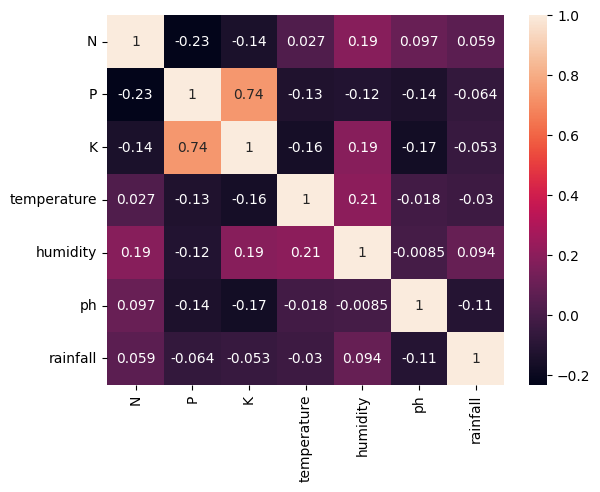

In [8]:
import seaborn as sns
sns.heatmap(corr_mat, annot=True)

In [9]:
crop_dict = {
"rice":	1,
"maize":2,
"chickpea":	3,
"kidneybeans"	:4,
"pigeonpeas":	5,
"mothbeans"	:6,
"mungbean":	7,
"blackgram"	:8,
"lentil":	9,
"pomegranate"	:10,
"banana":	11,
"mango":12,
"grapes":	13,
"watermelon"	:14,
"muskmelon":15,
"apple"	:16,
"orange":	17,
"papaya"	:18,
"coconut":	19,
"cotton"	:20,
"jute":	21,
"coffee"	:22
}

In [10]:
df['label_val'] = df['label'].map(crop_dict)
df["label_val"].value_counts()

,count
label_val,
1,100
2,100
3,100
4,100
5,100
6,100
7,100
8,100
9,100


In [11]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label,label_val
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,1
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,1
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,1
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,1
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,1


In [12]:
# test and split
X = df.drop(['label','label_val'], axis=1)
y = df['label_val']
X,y

(        N   P   K  temperature   humidity        ph    rainfall
 0      90  42  43    20.879744  82.002744  6.502985  202.935536
 1      85  58  41    21.770462  80.319644  7.038096  226.655537
 2      60  55  44    23.004459  82.320763  7.840207  263.964248
 3      74  35  40    26.491096  80.158363  6.980401  242.864034
 4      78  42  42    20.130175  81.604873  7.628473  262.717340
 ...   ...  ..  ..          ...        ...       ...         ...
 2195  107  34  32    26.774637  66.413269  6.780064  177.774507
 2196   99  15  27    27.417112  56.636362  6.086922  127.924610
 2197  118  33  30    24.131797  67.225123  6.362608  173.322839
 2198  117  32  34    26.272418  52.127394  6.758793  127.175293
 2199  104  18  30    23.603016  60.396475  6.779833  140.937041
 
 [2200 rows x 7 columns],
 0        1
 1        1
 2        1
 3        1
 4        1
         ..
 2195    22
 2196    22
 2197    22
 2198    22
 2199    22
 Name: label_val, Length: 2200, dtype: int64)

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1760, 7), (440, 7), (1760,), (440,))

In [14]:
X_train, y_train

(        N    P    K  temperature   humidity        ph    rainfall
 1656   17   16   14    16.396243  92.181519  6.625539  102.944161
 752    37   79   19    27.543848  69.347863  7.143943   69.408782
 892     7   73   25    27.521856  63.132153  7.288057   45.208411
 1041  101   70   48    25.360592  75.031933  6.012697  116.553145
 1179    0   17   30    35.474783  47.972305  6.279134   97.790725
 ...   ...  ...  ...          ...        ...       ...         ...
 1638   10    5    5    21.213070  91.353492  7.817846  112.983436
 1095  108   94   47    27.359116  84.546250  6.387431   90.812505
 1130   11   36   31    27.920633  51.779659  6.475449  100.258567
 1294   11  124  204    13.429886  80.066340  6.361141   71.400430
 860    32   78   22    23.970814  62.355576  7.007038   53.409060
 
 [1760 rows x 7 columns],
 1656    17
 752      8
 892      9
 1041    11
 1179    12
         ..
 1638    17
 1095    11
 1130    12
 1294    13
 860      9
 Name: label_val, Length: 1760, dtyp

In [15]:
# standardization
from sklearn.preprocessing import MinMaxScaler
mms = MinMaxScaler()
X_train = mms.fit_transform(X_train)
X_test = mms.transform(X_test)
X_train, X_test

(array([[0.12142857, 0.07857143, 0.045     , ..., 0.9089898 , 0.48532225,
         0.29685161],
        [0.26428571, 0.52857143, 0.07      , ..., 0.64257946, 0.56594073,
         0.17630752],
        [0.05      , 0.48571429, 0.1       , ..., 0.57005802, 0.58835229,
         0.08931844],
        ...,
        [0.07857143, 0.22142857, 0.13      , ..., 0.43760347, 0.46198144,
         0.28719815],
        [0.07857143, 0.85      , 0.995     , ..., 0.76763665, 0.44420505,
         0.18346657],
        [0.22857143, 0.52142857, 0.085     , ..., 0.56099735, 0.54465022,
         0.11879596]]),
 array([[0.72142857, 0.08571429, 0.21      , ..., 0.93872187, 0.41682113,
         0.021381  ],
        [0.7       , 0.02142857, 0.23      , ..., 0.84296447, 0.42837304,
         0.10449492],
        [0.42142857, 0.40714286, 0.22      , ..., 0.92264534, 0.5344578 ,
         0.33938901],
        ...,
        [0.86428571, 0.3       , 0.055     , ..., 0.75864563, 0.6560289 ,
         0.18741185],
        [0.8

In [16]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_test = ss.transform(X_test)
X_train, X_test

(array([[-9.03426596e-01, -1.12616170e+00, -6.68506601e-01, ...,
          9.36586183e-01,  1.93473784e-01,  5.14970176e-03],
        [-3.67051340e-01,  7.70358846e-01, -5.70589522e-01, ...,
         -1.00470485e-01,  8.63917548e-01, -6.05290566e-01],
        [-1.17161422e+00,  5.89737842e-01, -4.53089028e-01, ...,
         -3.82774991e-01,  1.05029771e+00, -1.04580687e+00],
        ...,
        [-1.06433917e+00, -5.24091685e-01, -3.35588533e-01, ...,
         -8.98381379e-01, -6.34357580e-04, -4.37358211e-02],
        [-1.06433917e+00,  2.12501638e+00,  3.05234239e+00, ...,
          3.86340190e-01, -1.48467347e-01, -5.69036842e-01],
        [-5.01145154e-01,  7.40255346e-01, -5.11839275e-01, ...,
         -4.18045489e-01,  6.86860180e-01, -8.96531475e-01]]),
 array([[ 1.34934948, -1.0960582 , -0.02225388, ...,  1.05232434,
         -0.37619899, -1.38984486],
        [ 1.26889319, -1.36698971,  0.05607978, ...,  0.67956909,
         -0.28013033, -0.96895253],
        [ 0.22296144,  0.

In [17]:
#train
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_selection = {
    "Decision Tree": DecisionTreeClassifier(),
    "Logistic Regression": LogisticRegression(),
    "Random Forest": RandomForestClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(),
    "GaussionNB": GaussianNB(),
    "ExtraTree": ExtraTreeClassifier()
}

for name, model in model_selection.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted') # Added average='weighted'
    recall = recall_score(y_test, y_pred, average='weighted') # Added average='weighted'
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(name)
    print(f" Accuracy: {accuracy}")
    print(f" Precision: {precision}")
    print(f" Recall: {recall}")
    print(f" F1 Score: {f1}")
    print()

Decision Tree
 Accuracy: 0.9818181818181818
 Precision: 0.9823312672176309
 Recall: 0.9818181818181818
 F1 Score: 0.9818088608800072

Logistic Regression
 Accuracy: 0.9636363636363636
 Precision: 0.9644420567548909
 Recall: 0.9636363636363636
 F1 Score: 0.9635115059268679

Random Forest
 Accuracy: 0.9931818181818182
 Precision: 0.9937348484848485
 Recall: 0.9931818181818182
 F1 Score: 0.9931754816901672

Gradient Boosting
 Accuracy: 0.9818181818181818
 Precision: 0.9842712842712842
 Recall: 0.9818181818181818
 F1 Score: 0.9818514668069126

AdaBoost
 Accuracy: 0.14545454545454545
 Precision: 0.0636061510428704
 Recall: 0.14545454545454545
 F1 Score: 0.07569998572208705

KNN
 Accuracy: 0.9659090909090909
 Precision: 0.970544879761387
 Recall: 0.9659090909090909
 F1 Score: 0.9659407741693837

Naive Bayes
 Accuracy: 0.9954545454545455
 Precision: 0.9958181818181818
 Recall: 0.9954545454545455
 F1 Score: 0.9954229797979799

SVM
 Accuracy: 0.9681818181818181
 Precision: 0.971517119244392
 Re

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [18]:
#model selecting
rfc = RandomForestClassifier()
rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)
accuracy_score(y_test, y_pred)

0.9954545454545455

In [19]:
def predict_crop(N,P,K,temp,humidity,ph,rainfall):
    data = np.array([[N,P,K,temp,humidity,ph,rainfall]])
    data = ss.transform(data)
    prediction = rfc.predict(data)
    return prediction[0]


In [20]:
crop_dict_reverse = {v: k for k, v in crop_dict.items()}
crop_dict_reverse

{1: 'rice',
 2: 'maize',
 3: 'chickpea',
 4: 'kidneybeans',
 5: 'pigeonpeas',
 6: 'mothbeans',
 7: 'mungbean',
 8: 'blackgram',
 9: 'lentil',
 10: 'pomegranate',
 11: 'banana',
 12: 'mango',
 13: 'grapes',
 14: 'watermelon',
 15: 'muskmelon',
 16: 'apple',
 17: 'orange',
 18: 'papaya',
 19: 'coconut',
 20: 'cotton',
 21: 'jute',
 22: 'coffee'}

In [36]:
N=10
P=20
K=30
temp=25.8
humidity=100
ph=3.5
rainfall=127
predict = predict_crop(N,P,K,temp,humidity,ph,rainfall)
print(predict)
if predict in crop_dict_reverse:
    print(f"Recommended crop: {crop_dict_reverse[predict]}")
else:
    print("Soory are not able to recommend a proper crop for this environment")
# print(crop_dict_reverse[predict])


16
Recommended crop: apple


In [22]:
import pickle
pickle.dump(rfc, open('model.pkl', 'wb'))

In [24]:
df.corr(numeric_only=True)

,N,P,K,temperature,humidity,ph,rainfall,label_val
N,1.000000,-0.231460,-0.140512,0.026504,0.190688,0.096683,0.059020,0.282787
P,-0.231460,1.000000,0.736232,-0.127541,-0.118734,-0.138019,-0.063839,-0.167951
K,-0.140512,0.736232,1.000000,-0.160387,0.190859,-0.169503,-0.053461,0.143703
temperature,0.026504,-0.127541,-0.160387,1.000000,0.205320,-0.017795,-0.030084,0.180571
humidity,0.190688,-0.118734,0.190859,0.205320,1.000000,-0.008483,0.094423,0.524452
ph,0.096683,-0.138019,-0.169503,-0.017795,-0.008483,1.000000,-0.109069,0.052389
rainfall,0.059020,-0.063839,-0.053461,-0.030084,0.094423,-0.109069,1.000000,0.121486
label_val,0.282787,-0.167951,0.143703,0.180571,0.524452,0.052389,0.121486,1.000000
